# The demand shock as a preference shock: sweeping $\zeta$

`planner_consumption_deviation.ipynb` treats the demand shock as an additive shifter
`dem` on the natural rate, with the preference shock only implicit. Here $\zeta$ is the
**primitive**: a path $z_t=\log\zeta_t$ is chosen, and everything else — the natural rate,
the consumption response, the planner's objective — is derived from it. Then $\zeta$ is
swept.

**The mapping.** With $U=\sum_t\beta^t\zeta_t\,[u(C_t)-v(N_t)]$ the household Euler equation is

$$c_t = c_{t+1}-\tfrac1\gamma\Big[i_t-\pi_{t+1}-\rho+(z_{t+1}-z_t)\Big],$$

so the object the parent notebook calls `dem` is exactly $z_{t+1}-z_t$, and
$r^n_t=\rho-\texttt{dem}_t+\gamma\Delta y^n_{t+1}$. Inverting, a one-period shifter $z_0$
gives $\texttt{dem}_0=-z_0$ and

$$r^n_0=\rho+z_0,\qquad c_0\big|_{i\equiv\rho}=\frac{z_0}{\gamma}.$$

Two consequences drive everything below. The consumption response is **linear** in $z_0$
with slope $1/\gamma$. And the natural rate goes negative once $z_0<-\rho$, i.e. for
shifters larger than $1\%$ — at which point the lower bound binds and the planner can no
longer attain the first best.

**What is held fixed.** Physical productivity never moves under a demand shock, so
$a^{\text{phys}}\equiv0$ and $y^e\equiv0$: the efficient level of consumption is the steady
state, whatever $\zeta$ is. This is the specification $\zeta_t$ multiplying the *whole*
period felicity — it cancels from $u'(C)A=v'(N)$, so it moves the intertemporal price and
not the efficient quantities. The alternative reading, $\zeta_t u(C_t)-v(N_t)$, is examined
in the last section.

Because $a^{\text{phys}}\equiv0$, the labour-elasticity question ($\varphi_{ya}$, $\alpha$)
is provably irrelevant here: $\varphi_{ya}$ multiplies only $a^{\text{phys}}$ in the target
and $\Delta a^{\text{nat}}$ in $r^n$, both of which are zero without time to build. So
$\alpha=1$ is used throughout without loss.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

Identical to `planner_consumption_deviation.ipynb`.

In [2]:
sigma = 5
beta = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (36.5 * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1

gamma = 2.0
eta = 2.0
PHI_YA = (1 + eta) / (gamma + eta)
chi = 1.0

T = 30
BOUNDS = (0.0, 0.05)          # the lower bound is what makes large zeta interesting

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA:.4f}, rho={rho:.6f}')
print(f'zero lower bound binds once r^n_0 = rho + z_0 < 0, i.e. z_0 < {-rho:.4f}'
      f'  (zeta_0 < {np.exp(-rho):.6f})')

gamma=2.0, eta=2.0, phi_ya=0.7500, rho=0.010000
zero lower bound binds once r^n_0 = rho + z_0 < 0, i.e. z_0 < -0.0100  (zeta_0 < 0.990050)


In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS = len(tvals)
Z_PHYS = c * (tvals + N_array)
print(f'c = {c:.7f}   mean tau = {tau.mean():.4f}   firms = {NFIRMS}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_62203/3757908769.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   mean tau = 2.8885   firms = 269


## 2. The model, with $\zeta$ as the primitive

`zeta_path` builds $z_t$; `solve` takes it and derives `dem` internally, so the two can
never drift apart. Two departures from the parent notebook, both deliberate:

1. **`welfare` weights by $\beta^t\zeta_t$.** The preference shock belongs in the objective
   it came from, not only in the Euler equation.
2. **The rate matrix keeps its history.** The parent's `disc_matrix` fills only the
   top-left $L\times L$ block, so a firm delivering at $t\ge L$ discounts at $\rho$ even
   when its production window sat inside the policy period. That lets the planner move
   firms' discount factors without later cohorts paying for it. Section 6 sizes the
   difference; it is irrelevant without time to build, where the discount block is
   identically one.

In [4]:
def zeta_path(z0, rho_zeta=0.0, T=T):
    """Log preference shifter. z_t = z0 * rho_zeta**t, normalised to 0 at the terminal date."""
    z = z0 * rho_zeta ** np.arange(T) if rho_zeta > 0 else np.r_[z0, np.zeros(T - 1)]
    return z - z[-1]


def dem_from_zeta(z):
    """dem_t = z_{t+1} - z_t, the slot the shock occupies in the Euler equation."""
    return np.r_[np.diff(z), 0.0]


def disc_matrix(r, T=T, time_to_build=True, truncated=False):
    L = len(r)
    ip = np.ones(T) * rho; ip[:L] = np.asarray(r, float)
    irl = np.ones((T, T)) * rho
    if truncated:                                  # the parent notebook's construction
        blk = np.full((L, L), rho, dtype=float)
        for i in range(L):
            blk[i, :i + 1] = np.asarray(r, float)[i::-1]
        irl[0:L, :L] = blk
    else:                                          # rows carry the rates that prevailed
        for t in range(T):
            for k in range(T):
                irl[t, k] = ip[t - k] if t - k >= 0 else rho
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    tv = tvals if time_to_build else np.zeros_like(tvals)
    return ce[:, tv]


def solve(r, z, time_to_build=False, truncated=False):
    """Demand shock only: physical productivity never moves, so y_eff = 0."""
    z = np.asarray(z, float)
    dem = dem_from_zeta(z)
    disc = disc_matrix(r, T, time_to_build, truncated)
    tprod = disc * Z_PHYS

    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))
    Z_t = np.sum(Z_PHYS**(sigma - 1) * np.ones((T, 1)), axis=1)**(1 / (sigma - 1))

    ip = np.ones(T) * rho; ip[:len(r)] = r
    a_nat = np.log(A_til) - np.log(A_til)[-1]
    d = np.log(A_til) - np.log(Z_t); d = d - d[-1]

    pi = np.zeros(T); pi[1:] = -(a_nat[1:] - a_nat[:-1])      # P = 1/Atil
    pi[0] = -a_nat[0]                                          # impact inflation counted
    pi_fwd = np.r_[pi[1:], 0.0]

    y_nat = PHI_YA * a_nat
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - dem + gamma * dy

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    x = x[:T]

    a_phys = a_nat - d
    return dict(x=x, i=ip, pi=pi, d=d, a_nat=a_nat, a_phys=a_phys, r_nat=r_nat,
                y_phys=x + y_nat - d, y_eff=PHI_YA * a_phys, z=z, dem=dem)


def welfare(s, use_zeta=True):
    """sum_t beta^t zeta_t [u(C) - v(N)] on the physical paths."""
    y, a = s['y_phys'], s['a_phys']
    w = beta_hh ** np.arange(len(y)) * (np.exp(s['z']) if use_zeta else 1.0)
    C = np.exp(y); Nl = np.exp(y - a)
    return float(np.sum(w * (C**(1 - gamma) / (1 - gamma)
                             - chi * Nl**(1 + eta) / (1 + eta))))


SEEDS = [lambda L: np.ones(L) * rho,
         lambda L: np.linspace(0.0, 0.015, L),
         lambda L: np.full(L, 0.005),
         lambda L: np.zeros(L)]


def optimal(z, L=8, time_to_build=False, use_zeta=True, truncated=False):
    """Best rate path over L free periods, best of several starting points."""
    def obj(r):
        return -welfare(solve(r, z, time_to_build, truncated), use_zeta)
    best = None
    for seed in SEEDS:
        res = minimize(obj, seed(L), method='L-BFGS-B', bounds=[BOUNDS] * L,
                       options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
        if best is None or res.fun < best.fun:
            best = res
    return best.x, solve(best.x, z, time_to_build, truncated)


def pct(v):
    """log deviation -> per cent deviation of the level."""
    return 100 * (np.exp(v) - 1)


print('model ready')

model ready


## 3. Does the mapping hold?

Before sweeping, check the two closed forms against the solver: $r^n_0=\rho+z_0$ and
$c_0=z_0/\gamma$ under a fixed rate.

In [5]:
print(f'{"zeta_0":>10}{"z_0":>10}{"r^n_0 model":>14}{"rho+z_0":>10}'
      f'{"c_0 fixed rate":>16}{"z_0/gamma":>11}')
print('-' * 71)
for z0 in [-0.002, -0.005, -0.01, -0.02, -0.03]:
    z = zeta_path(z0)
    s = solve(np.ones(3) * rho, z)
    print(f'{np.exp(z0):>10.6f}{z0:>10.4f}{100*s["r_nat"][0]:>13.4f}%'
          f'{100*(rho+z0):>9.4f}%{pct(s["y_phys"])[0]:>15.4f}%{100*z0/gamma:>10.4f}%')
print('\n-> both exact.  The consumption response is linear in z_0 with slope 1/gamma,')
print('   and the natural rate crosses zero at z_0 = -rho = -0.01.')

    zeta_0       z_0   r^n_0 model   rho+z_0  c_0 fixed rate  z_0/gamma
-----------------------------------------------------------------------
  0.998002   -0.0020       0.8000%   0.8000%        -0.1000%   -0.1000%
  0.995012   -0.0050       0.5000%   0.5000%        -0.2497%   -0.2500%
  0.990050   -0.0100       0.0000%   0.0000%        -0.4988%   -0.5000%
  0.980199   -0.0200      -1.0000%  -1.0000%        -0.9950%   -1.0000%
  0.970446   -0.0300      -2.0000%  -2.0000%        -1.4888%   -1.5000%

-> both exact.  The consumption response is linear in z_0 with slope 1/gamma,
   and the natural rate crosses zero at z_0 = -rho = -0.01.


## 4. Sweeping $\zeta$: what does the planner do?

$z_0$ from $-0.2\%$ to $-4\%$, one-period shock, no time to build. Each point is solved
twice — with and without $\zeta$ in the objective — to keep the two channels separate:
$\zeta$ enters the *constraint* through $r^n$ and the *objective* through the weights.

In [6]:
Z0_GRID = -np.linspace(0.002, 0.04, 20)
sweep = []
for z0 in Z0_GRID:
    z = zeta_path(z0)
    s_base = solve(np.ones(3) * rho, z)
    row = dict(z0=z0, zeta0=np.exp(z0), rn0=s_base['r_nat'][0],
               c_fixed=pct(s_base['y_phys']).min())
    for tag, uz in [('on', True), ('off', False)]:
        r_opt, s_opt = optimal(z, L=8, use_zeta=uz)
        row[f'i_{tag}'] = r_opt
        row[f'c_{tag}'] = pct(s_opt['y_phys'])
        row[f'gap_{tag}'] = np.max(np.abs(s_opt['y_phys'] - s_opt['y_eff']))
        row[f'U_{tag}'] = welfare(s_opt, uz)
    row['U_base'] = welfare(s_base, True)
    sweep.append(row)

print(f'{"zeta_0":>9}{"z_0 %":>8}{"r^n_0 %":>9}{"c fixed %":>11}{"i_0 %":>8}'
      f'{"i_1 %":>8}{"c_0 plan %":>12}{"peak gap":>11}{"ZLB":>5}')
print('-' * 81)
for r in sweep:
    zlb = 'yes' if r['rn0'] < 0 else ''
    print(f'{r["zeta0"]:>9.5f}{100*r["z0"]:>8.2f}{100*r["rn0"]:>9.4f}{r["c_fixed"]:>11.4f}'
          f'{100*r["i_on"][0]:>8.4f}{100*r["i_on"][1]:>8.4f}{r["c_on"][0]:>12.4f}'
          f'{r["gap_on"]:>11.2e}{zlb:>5}')

   zeta_0   z_0 %  r^n_0 %  c fixed %   i_0 %   i_1 %  c_0 plan %   peak gap  ZLB
---------------------------------------------------------------------------------
  0.99800   -0.20   0.8000    -0.1000  0.8000  1.0000      0.0000   1.57e-07     
  0.99601   -0.40   0.6000    -0.1998  0.6000  1.0000     -0.0000   1.12e-07     
  0.99402   -0.60   0.4000    -0.2996  0.4000  1.0000      0.0000   1.66e-07     
  0.99203   -0.80   0.2000    -0.3992  0.2000  1.0000      0.0000   1.70e-07     
  0.99005   -1.00   0.0000    -0.4988  0.0000  1.0000      0.0000   1.74e-07     
  0.98807   -1.20  -0.2000    -0.5982  0.0000  0.9002     -0.0501   5.01e-04  yes
  0.98610   -1.40  -0.4000    -0.6976  0.0000  0.8006     -0.1002   1.00e-03  yes
  0.98413   -1.60  -0.6000    -0.7968  0.0000  0.7014     -0.1506   1.51e-03  yes
  0.98216   -1.80  -0.8000    -0.8960  0.0000  0.6024     -0.2010   2.01e-03  yes
  0.98020   -2.00  -1.0000    -0.9950  0.0000  0.5038     -0.2516   2.52e-03  yes
  0.97824   -2.2

### The kink

Two regimes, and the boundary is exactly where the natural rate hits zero.

In [7]:
unc = [r for r in sweep if r['rn0'] >= 0]
con = [r for r in sweep if r['rn0'] < 0]
print(f'unconstrained points: {len(unc)}   constrained (ZLB) points: {len(con)}')
print(f'\nunconstrained: does i_0 = r^n_0 exactly?')
for r in unc[:4]:
    print(f'   zeta_0={r["zeta0"]:.5f}   i_0={100*r["i_on"][0]:.5f}%   '
          f'r^n_0={100*r["rn0"]:.5f}%   peak gap={r["gap_on"]:.2e}')
print(f'\nconstrained: i_0 pinned at the bound, and the planner spends later periods')
for r in con[::4]:
    below = int(np.sum(r['i_on'] < rho - 1e-9))
    print(f'   zeta_0={r["zeta0"]:.5f}   i[:4]={np.round(100*r["i_on"][:4],4)}   '
          f'periods below rho: {below}   c trough={r["c_on"].min():.4f}%   '
          f'gap={r["gap_on"]:.2e}')

unconstrained points: 5   constrained (ZLB) points: 15

unconstrained: does i_0 = r^n_0 exactly?
   zeta_0=0.99800   i_0=0.80000%   r^n_0=0.80000%   peak gap=1.57e-07
   zeta_0=0.99601   i_0=0.60001%   r^n_0=0.60000%   peak gap=1.12e-07
   zeta_0=0.99402   i_0=0.39999%   r^n_0=0.40000%   peak gap=1.66e-07
   zeta_0=0.99203   i_0=0.19999%   r^n_0=0.20000%   peak gap=1.70e-07

constrained: i_0 pinned at the bound, and the planner spends later periods
   zeta_0=0.98807   i[:4]=[0.     0.9002 1.     1.    ]   periods below rho: 5   c trough=-0.0501%   gap=5.01e-04
   zeta_0=0.98020   i[:4]=[0.     0.5038 1.     1.    ]   periods below rho: 4   c trough=-0.2516%   gap=2.52e-03
   zeta_0=0.97239   i[:4]=[0.     0.1122 1.     1.    ]   periods below rho: 5   c trough=-0.4551%   gap=4.56e-03
   zeta_0=0.96464   i[:4]=[0.     0.     0.8172 1.    ]   periods below rho: 5   c trough=-0.7061%   gap=7.09e-03


### How much does $\zeta$-in-the-objective matter?

The thing to separate: $\zeta$ in $r^n$ is first order, $\zeta$ in the weights is second
order. If the first best is attainable the weights cannot matter at all — any positively
weighted sum agrees about an allocation that maximises every period at once. Where the
bound binds they can, and this is where to look.

In [8]:
print(f'{"zeta_0":>9}{"|di| max (bp)":>15}{"|dc| max (bp)":>15}{"first best?":>13}')
print('-' * 52)
for r in sweep:
    di = 1e4 * np.max(np.abs(r['i_on'] - r['i_off']))
    dc = 1e2 * np.max(np.abs(r['c_on'] - r['c_off']))
    fb = 'yes' if r['gap_on'] < 1e-6 else 'no'
    print(f'{r["zeta0"]:>9.5f}{di:>15.4f}{dc:>15.4f}{fb:>13}')
print('\n-> zero to numerical precision wherever the first best is reached; small but')
print('   non-zero once the bound binds, and always of the order of |z_0| itself.')

   zeta_0  |di| max (bp)  |dc| max (bp)  first best?
----------------------------------------------------
  0.99800         0.0063         0.0024          yes
  0.99601         0.0047         0.0015          yes
  0.99402         0.0041         0.0013          yes
  0.99203         0.0030         0.0012          yes
  0.99005         0.0100         0.0033          yes
  0.98807         0.0610         0.0306           no
  0.98610         0.1391         0.0698           no
  0.98413         0.2424         0.1204           no
  0.98216         0.3621         0.1813           no
  0.98020         0.5007         0.2508           no
  0.97824         0.6611         0.3313           no
  0.97629         0.8388         0.4215           no
  0.97434         1.0374         0.5214           no
  0.97239         1.2602         0.6329           no
  0.97045         1.5033         0.7545           no
  0.96851         1.2050         0.6064           no
  0.96657         1.4375         0.7212       

## 5. Persistence

Everything so far is a one-period shifter, which is what `D_SHOCK` at $t=0$ implies. A
persistent shifter $z_t=z_0\rho_\zeta^t$ is a different object, and it cuts the opposite
way from what one might guess. Because `dem` is the *first difference* of $z$,

$$\texttt{dem}_0=z_1-z_0=z_0(\rho_\zeta-1)\quad\Longrightarrow\quad
r^n_0=\rho+z_0(1-\rho_\zeta),$$

so for a fixed $z_0$ **persistence shrinks the impact drop in the natural rate** — the same
total shifter is spread over more periods. The bound therefore binds *less*, not more. What
grows instead is the number of periods over which policy has to respond, so the binding
constraint migrates from the lower bound to the length of the free horizon $L$. Both
diagnostics are reported below so the two cannot be confused.

In [9]:
Z0_FIX = -0.02
L_P = 20
print(f'z_0 = {Z0_FIX} (zeta_0 = {np.exp(Z0_FIX):.6f}) held fixed; varying persistence')
print(f'free periods L = {L_P}\n')
print(f'{"rho_zeta":>9}{"r^n[:4] (%)":>32}{"i[:4] (%)":>32}{"c trough %":>12}'
      f'{"gap":>10}{"ZLB?":>6}{"|i_L - rho| bp":>16}')
print('-' * 118)
persist = {}
for rz in [0.0, 0.3, 0.6, 0.9]:
    z = zeta_path(Z0_FIX, rz)
    s_b = solve(np.ones(3) * rho, z)
    r_opt, s_o = optimal(z, L=L_P)
    persist[rz] = (z, r_opt, s_o, s_b)
    zlb = 'yes' if np.any(np.isclose(r_opt, 0.0, atol=1e-9)) else ''
    tail = 1e4 * abs(r_opt[-1] - rho)      # horizon still binding if the last free rate != rho
    print(f'{rz:>9.1f}{str(np.round(100*s_b["r_nat"][:4],3)):>32}'
          f'{str(np.round(100*r_opt[:4],3)):>32}'
          f'{pct(s_o["y_phys"]).min():>12.4f}'
          f'{np.max(np.abs(s_o["y_phys"]-s_o["y_eff"])):>10.2e}{zlb:>6}{tail:>16.2f}')
print('\n-> r^n_0 = rho + z_0(1 - rho_zeta), so persistence RAISES the impact natural rate')
print('   and the bound stops binding: at rho_zeta = 0.6 the path is interior throughout')
print('   and the first best is attained.  At rho_zeta = 0.9 the bound is slack as well,')
print('   but the shock outlives the free horizon -- the last free rate is still far from')
print('   rho, so what binds there is L, not the ZLB.  The two constraints have to be read')
print('   off separately; a large residual gap alone does not tell you which one it is.')

z_0 = -0.02 (zeta_0 = 0.980199) held fixed; varying persistence
free periods L = 20

 rho_zeta                     r^n[:4] (%)                       i[:4] (%)  c trough %       gap  ZLB?  |i_L - rho| bp
----------------------------------------------------------------------------------------------------------------------


      0.0               [-1.  1.  1.  1.]       [0.    0.504 1.    1.   ]     -0.2516  2.52e-03   yes            0.00


      0.3   [-0.4    0.58   0.874  0.962]       [0.    0.381 0.874 0.962]     -0.1002  1.00e-03   yes            0.00


      0.6       [0.2   0.52  0.712 0.827]       [0.2   0.52  0.712 0.827]     -0.0000  3.62e-07                  0.01


      0.9       [0.8   0.82  0.838 0.854]       [0.8   0.82  0.838 0.854]     -0.0744  7.45e-04                 17.60

-> r^n_0 = rho + z_0(1 - rho_zeta), so persistence RAISES the impact natural rate
   and the bound stops binding: at rho_zeta = 0.6 the path is interior throughout
   and the first best is attained.  At rho_zeta = 0.9 the bound is slack as well,
   but the shock outlives the free horizon -- the last free rate is still far from
   rho, so what binds there is L, not the ZLB.  The two constraints have to be read
   off separately; a large residual gap alone does not tell you which one it is.


## 6. With time to build

Same sweep, but firms now discount over their production lag, so the rate feeds into
prices and `d` is no longer zero. Also shown: what the parent notebook's truncated rate
matrix would give, since that is the construction its results rest on.

In [10]:
print(f'{"zeta_0":>9}{"ttb":>6}{"trunc":>7}{"i[:3] (%)":>28}{"c trough %":>12}{"gap":>11}')
print('-' * 75)
ttb_rows = {}
for z0 in [-0.005, -0.01, -0.02, -0.03]:
    z = zeta_path(z0)
    for ttb, tr in [(False, False), (True, False), (True, True)]:
        r_opt, s_o = optimal(z, L=8, time_to_build=ttb, truncated=tr)
        ttb_rows[(z0, ttb, tr)] = (r_opt, s_o)
        print(f'{np.exp(z0):>9.5f}{str(ttb):>6}{str(tr):>7}{str(np.round(100*r_opt[:3],4)):>28}'
              f'{pct(s_o["y_phys"]).min():>12.4f}{np.max(np.abs(s_o["y_phys"]-s_o["y_eff"])):>11.2e}')
    print()
print('-> the truncated matrix flatters the planner: it can move d in the free periods')
print('   without later cohorts discounting at the rates that actually prevailed.')

   zeta_0   ttb  trunc                   i[:3] (%)  c trough %        gap
---------------------------------------------------------------------------


  0.99501 False  False               [0.5 1.  1. ]     -0.0000   1.37e-07


  0.99501  True  False      [0.8115 0.7211 1.1251]     -0.0470   4.70e-04


  0.99501  True   True      [0.6221 0.8322 1.0132]     -0.0000   1.94e-07



  0.99005 False  False                  [0. 1. 1.]     -0.0000   1.74e-07


...

  0.98020  True  False      [0.1446 0.     1.3788]     -0.1949   1.95e-03


  0.98020  True   True      [0.     0.     1.3999]     -0.0284   3.95e-04



  0.97045 False  False         [0.    0.015 1.   ]     -0.5062   5.08e-03


  0.97045  True  False      [0.     0.     0.9861]     -0.3210   3.21e-03


  0.97045  True   True         [0.    0.    0.994]     -0.2861   2.87e-03

-> the truncated matrix flatters the planner: it can move d in the free periods
   without later cohorts discounting at the rates that actually prevailed.


## 7. Figures

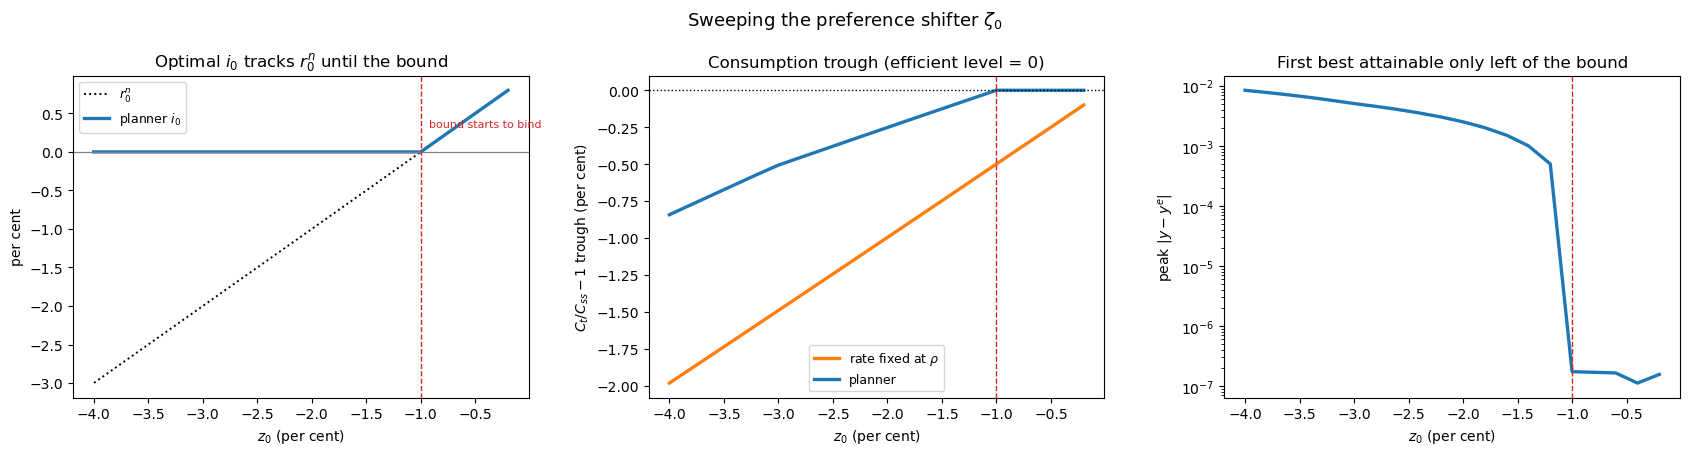

In [11]:
H = 12
z0s = np.array([r['z0'] for r in sweep])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

ax = axes[0]
ax.plot(100*z0s, [100*r['rn0'] for r in sweep], 'k:', lw=1.4, label=r'$r^n_0$')
ax.plot(100*z0s, [100*r['i_on'][0] for r in sweep], 'C0-', lw=2.4, label=r'planner $i_0$')
ax.axhline(0, color='grey', lw=0.9)
ax.axvline(-100*rho, color='C3', lw=1.0, ls='--')
ax.annotate('bound starts to bind', xy=(-100*rho, 0), xytext=(6, 18),
            textcoords='offset points', fontsize=8, color='C3')
ax.set_xlabel(r'$z_0$ (per cent)'); ax.set_ylabel('per cent')
ax.set_title(r'Optimal $i_0$ tracks $r^n_0$ until the bound')
ax.legend(fontsize=9)

ax = axes[1]
ax.plot(100*z0s, [r['c_fixed'] for r in sweep], 'C1-', lw=2.4, label=r'rate fixed at $\rho$')
ax.plot(100*z0s, [r['c_on'].min() for r in sweep], 'C0-', lw=2.4, label='planner')
ax.axhline(0, color='k', lw=1.0, ls=':')
ax.axvline(-100*rho, color='C3', lw=1.0, ls='--')
ax.set_xlabel(r'$z_0$ (per cent)'); ax.set_ylabel(r'$C_t/C_{ss}-1$ trough (per cent)')
ax.set_title('Consumption trough (efficient level = 0)')
ax.legend(fontsize=9)

ax = axes[2]
ax.semilogy(100*z0s, [max(r['gap_on'], 1e-12) for r in sweep], 'C0-', lw=2.4)
ax.axvline(-100*rho, color='C3', lw=1.0, ls='--')
ax.set_xlabel(r'$z_0$ (per cent)'); ax.set_ylabel(r'peak $|y-y^e|$')
ax.set_title('First best attainable only left of the bound')

fig.suptitle(r'Sweeping the preference shifter $\zeta_0$', fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_zeta_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

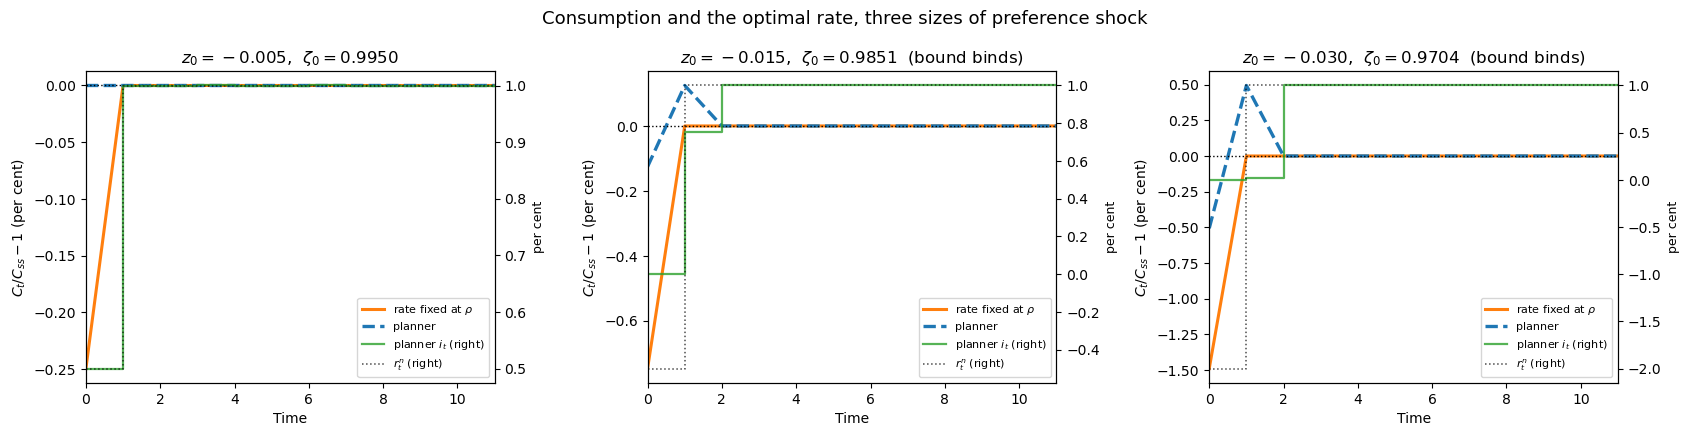

In [12]:
picks = [-0.005, -0.015, -0.03]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
t = np.arange(H)
for k, z0 in enumerate(picks):
    z = zeta_path(z0)
    s_b = solve(np.ones(3) * rho, z)
    r_o, s_o = optimal(z, L=8)
    ax = axes[k]
    ax.plot(t, pct(s_b['y_phys'])[:H], 'C1-', lw=2.2, label=r'rate fixed at $\rho$')
    ax.plot(t, pct(s_o['y_phys'])[:H], 'C0--', lw=2.4, label='planner')
    ax.axhline(0, color='k', lw=1.0, ls=':')
    ax2 = ax.twinx()
    ax2.step(t, 100*s_o['i'][:H], where='post', color='C2', lw=1.6, alpha=0.8,
             label=r'planner $i_t$ (right)')
    ax2.step(t, 100*s_b['r_nat'][:H], where='post', color='k', lw=1.1, ls=':',
             alpha=0.7, label=r'$r^n_t$ (right)')
    ax2.set_ylabel('per cent', fontsize=9)
    ax.set_xlim(0, H-1)
    ax.set_xlabel('Time'); ax.set_ylabel(r'$C_t/C_{ss}-1$ (per cent)')
    ax.set_title(rf'$z_0={z0:.3f}$,  $\zeta_0={np.exp(z0):.4f}$'
                 + ('  (bound binds)' if rho + z0 < 0 else ''))
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1+h2, l1+l2, fontsize=8, loc='lower right')

fig.suptitle('Consumption and the optimal rate, three sizes of preference shock', fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_zeta_irf.png', dpi=150, bbox_inches='tight')
plt.show()

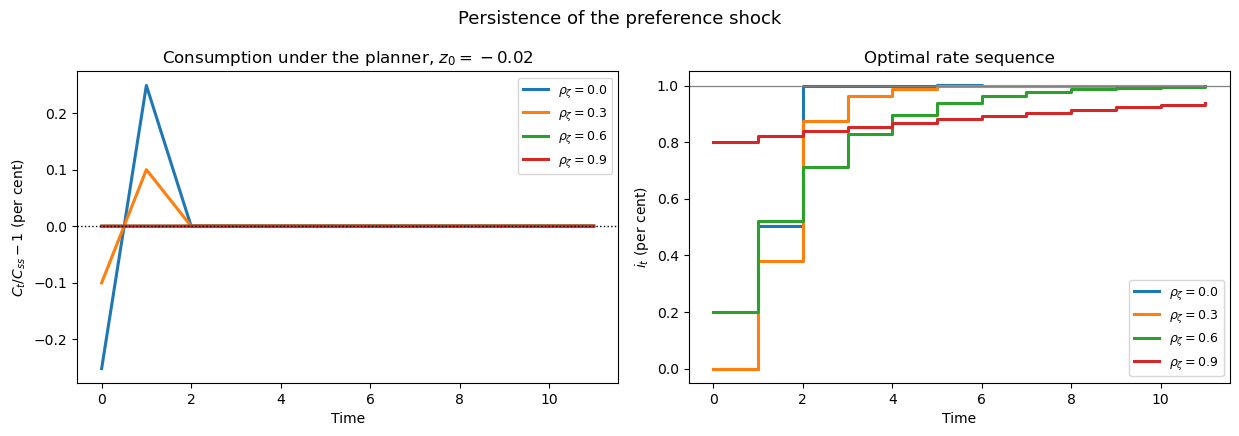

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for rz, (z, r_opt, s_o, s_b) in persist.items():
    lab = rf'$\rho_\zeta={rz:.1f}$'
    axes[0].plot(np.arange(H), pct(s_o['y_phys'])[:H], lw=2.2, label=lab)
    axes[1].step(np.arange(H), 100*s_o['i'][:H], where='post', lw=2.2, label=lab)
axes[0].axhline(0, color='k', lw=1.0, ls=':')
axes[0].set_xlabel('Time'); axes[0].set_ylabel(r'$C_t/C_{ss}-1$ (per cent)')
axes[0].set_title(rf'Consumption under the planner, $z_0={Z0_FIX}$')
axes[0].legend(fontsize=9)
axes[1].axhline(100*rho, color='grey', lw=0.9)
axes[1].set_xlabel('Time'); axes[1].set_ylabel('$i_t$ (per cent)')
axes[1].set_title('Optimal rate sequence')
axes[1].legend(fontsize=9)
fig.suptitle(r'Persistence of the preference shock', fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_zeta_persistence.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. The other reading of $\zeta$

Everything above assumes $\zeta_t$ multiplies the whole period felicity,
$\zeta_t[u(C_t)-v(N_t)]$. Then it cancels from $u'(C)A=v'(N)$, the efficient level of
consumption is the steady state for any $\zeta$, and the planner's job is to hold
consumption still.

Under $\zeta_t u(C_t)-v(N_t)$ — a shifter on the marginal utility of consumption alone —
it does not cancel: $v'(N)=\zeta_t u'(C_t)A$, so

$$c^e_0=\frac{z_0}{\gamma+\eta},$$

against a fixed-rate response of $z_0/\gamma$. The planner should then leave a fraction
$\eta/(\gamma+\eta)$ of the fall alone — with $\gamma=\eta=2$, exactly half — and offset
only the rest.

In [14]:
print(f'{"z_0 %":>8}{"c fixed (z/gamma) %":>22}{"c efficient (z/(g+eta)) %":>27}'
      f'{"planner should offset %":>25}')
print('-' * 82)
for z0 in [-0.005, -0.01, -0.02, -0.03]:
    cf, ce = 100*z0/gamma, 100*z0/(gamma+eta)
    print(f'{100*z0:>8.2f}{cf:>22.4f}{ce:>27.4f}{cf-ce:>25.4f}')
print(f'\n-> fraction left alone = eta/(gamma+eta) = {eta/(gamma+eta):.4f}')
print('   Under this reading the notebook\'s "planner removes the demand shock outright"')
print('   is wrong by that factor.  Which reading is right is a modelling choice, not')
print('   something the code can settle -- it is not implemented here.')

   z_0 %   c fixed (z/gamma) %  c efficient (z/(g+eta)) %  planner should offset %
----------------------------------------------------------------------------------
   -0.50               -0.2500                    -0.1250                  -0.1250
   -1.00               -0.5000                    -0.2500                  -0.2500
   -2.00               -1.0000                    -0.5000                  -0.5000
   -3.00               -1.5000                    -0.7500                  -0.7500

-> fraction left alone = eta/(gamma+eta) = 0.5000
   Under this reading the notebook's "planner removes the demand shock outright"
   is wrong by that factor.  Which reading is right is a modelling choice, not
   something the code can settle -- it is not implemented here.


## Summary

$\zeta$ made primitive, then swept.

1. **The mapping is exact and linear.** $r^n_0=\rho+z_0$ and $c_0|_{i\equiv\rho}=z_0/\gamma$,
   both confirmed against the solver. A $1\%$ shifter buys a $0.5\%$ consumption response
   at $\gamma=2$.

2. **Two regimes, with a kink at $z_0=-\rho$.** While $r^n_0\ge0$ the planner sets
   $i_0=r^n_0$ exactly and attains the first best — consumption never moves, and the whole
   response is a change in the intertemporal price. Once $z_0<-\rho$ the bound binds, $i_0$
   is pinned at zero, and the planner substitutes *later* accommodation: it holds the rate
   below $\rho$ for several periods and converts a large one-period shortfall into a
   smaller one spread over several. The first best is no longer attainable and the residual
   gap grows with $|z_0|$.

3. **$\zeta$ in the objective is second order, always.** Identical to numerical precision
   wherever the first best is reached — a positively weighted sum cannot disagree about an
   allocation that maximises every period at once — and, where the bound binds, of the
   order of $|z_0|$ itself. It moves the answer in the expected direction, tolerating a
   larger period-$0$ shortfall because period $0$ is worth less, but it is never the story.
   The shock matters through the constraint, not through the weights.

4. **Persistence relaxes the bound and tightens the horizon.** `dem` is the first
   difference of $z$, so $r^n_0=\rho+z_0(1-\rho_\zeta)$: for a fixed $z_0$ a more
   persistent shifter has a *smaller* impact effect on the natural rate, and the lower
   bound stops binding — at $\rho_\zeta=0.6$ the path is interior and the first best is
   attained. What replaces it is the free horizon: at $\rho_\zeta=0.9$ the bound is slack
   but the shock outlives $L$, and the residual gap is a horizon artefact rather than a
   ZLB result. Section 5 reports both diagnostics because the gap alone does not
   distinguish them.

5. **Time to build makes the planner's job harder, and the parent notebook's truncated rate
   matrix hides that.** With rows carrying the rates that actually prevailed, the planner
   loses the ability to move $d$ in the free periods without later cohorts paying for it.

The open modelling choice is section 8: whether $\zeta$ multiplies $v(N)$ as well as
$u(C)$. Everything here assumes it does. If it does not, the efficient consumption
response is $z_0/(\gamma+\eta)$ rather than zero and the planner should accommodate half
the shock rather than none of it.